# Dataset #4: NBA Player Per-Game Stats, 2014-15 to 2025-26 Regular Seasons

- **Dataset name:** NBA Stats API, `leagueleaders` endpoint (per-game stats, regular season)
- **Link:** https://stats.nba.com/stats/leagueleaders (we followed the request format from the `pseudo-r/Public-NBA-API` project)
- **Saved as:** `data-files/00-raw/nba_league_leaders_raw.csv` (raw) and `data-files/02-processed/nba_player_stats_cleaned.csv` (cleaned) (collected 11/8/2026)
- **Number of observations:** 2,996 rows (one row per player per season, 850 different players, 12 seasons)
- **Number of variables:** 29 (25 from the API, plus 4 we added: `season_label`, `season`, `pts_per_min`, `pts_outlier`)
- **How we collected it:** We used Python's `requests` library to ask the NBA Stats API for the regular season of each of the 12 seasons from 2014-15 to 2025-26, sorted by points per game. The API only answers requests that include certain headers (`x-nba-stats-origin` and `x-nba-stats-token`), so we added them. We waited 3 seconds between requests, added a `SEASON` column to each answer, stacked the 12 tables, and saved the result without other changes in `data-files/00-raw/`. The API only returns players who qualify for its leaderboard, which matters for the concerns below. (We also tried the `leaguedashplayerstats` endpoint, which lists every player, but it did not respond to our scripted requests, so we kept the leaderboard.)

This dataset covers the on-court performance part of our research question. It tells us how much each player scored, rebounded, passed, and played in each regular season, which gives us the performance side to compare with contracts and offseason trades.

## 2A. Important variables, units, and what they mean

| Variable | Units | What it means |
|---|---|---|
| `season_label` | text | The season, like `2024-25`. It came from the `SEASON` column we added when we downloaded each season. |
| `season` | year (whole number) | **Added by us.** The year the season **starts** (`2024` for 2024-25), so it is a number we can sort and compare. This matches `season_year` in Datasets #5 and #6, so the tables join on the same season. |
| `player_id` | whole number | The NBA's own ID for the player (Shai Gilgeous-Alexander = `1628983`). A player appears once per season. |
| `player` | text | The player's name. |
| `team_id`, `team` | whole number, text | The NBA's team ID and 3-letter team code (`OKC`, `MIL`). |
| `rank` | whole number | Rank by points per game **within that season**, starting at 1. |
| `gp` | games | Games played. A team plays 82 games, and the values here go from 45 to 84 (see 3C and 3E). |
| `min` | minutes per game | Average minutes on the court. |
| `fgm`, `fga`, `fg_pct` | shots per game, ratio | Field goals made, attempted, and the share made (0 to 1). `fg3_*` is the same for 3-pointers and `ft_*` for free throws. |
| `oreb`, `dreb`, `reb` | rebounds per game | Offensive, defensive, and total rebounds. |
| `ast`, `stl`, `blk`, `tov` | per game | Assists, steals, blocks, and turnovers. |
| `pts` | points per game | Average points scored. For example, Shai Gilgeous-Alexander averaged 32.7 in 2024-25. |
| `eff` | score | The NBA's simple efficiency score, which adds up good box-score actions and subtracts misses and turnovers. Higher is better. |
| `pts_per_min` | points per minute | **Added by us.** `pts / min`, rounded to 3 decimals. It tells us how much a player scores for each minute on the court. It is a scoring *rate*, not shooting efficiency. |
| `pts_outlier` | True / False | **Added by us.** Marks a player-season where `pts` is far above the other players **in the same season** (see 3E). We keep these rows. |

## 2B. Concerns with this dataset

1. **Only regular season.** Playoff games have shorter rotations and tougher defense, so a good regular-season scorer may look different in the playoffs. Playoff results are not in this dataset and will come from another source.
2. **Only qualified players are included.** The API leaves out players with few games (the lowest `gp` is 45), so bench players and injured players are missing. These may be exactly the players most likely to be traded, so on its own this dataset would bias our results toward regular players. To cover them, we will take regular-season stats for players who are not on the leaderboard from Dataset #2 (Kaggle box scores), which has a game log for every player who appeared in a game. Both datasets use the NBA's player IDs (`player_id` here, `personId` in Dataset #2), so we can tell which players are missing here and fill them in from Dataset #2.
3. **The number of players changes by season.** There are between 228 and 271 players per season, and some teams have far fewer qualified players than others. This is not missing data, but it means teams and seasons are not equally represented.
4. **Some seasons were shorter.** The 2019-20 and 2020-21 seasons had fewer games, so `gp` is not comparable across seasons. Per-game averages like `pts` and `min` are still comparable.
5. **The same player appears in many seasons.** 850 players make up 2,996 rows, so rows from the same player are not independent. We need to keep this in mind when we build and test a model.
6. **One team per row.** Each row lists one `team`. Some rows have `gp` above 82, which suggests the stats of a player who played for more than one team are combined. We have not yet checked which team is listed for these players (see 3E).
7. **Scoring changes over the years.** Pace and 3-point shooting have changed since 2014-15, so we flag scoring outliers within each season and not across all seasons together.
8. **No contract or trade information.** There is no salary, contract length, or trade history, so this dataset covers only the performance side of our question.
9. **Minutes affect every stat.** Players who play more minutes pile up more points and rebounds, so we added `pts_per_min` to compare players on a fairer scale. A high value in few minutes can still be noise.

## Setup

All file paths come from `nba_cleaning_utils.py`, which points at the `data-files/` folder (`RAW` = `00-raw/`, `INTERIM` = `01-interim/`, `PROCESSED` = `02-processed/`).

In [1]:
import os
import time

import requests
import pandas as pd
import matplotlib.pyplot as plt

from nba_cleaning_utils import RAW, INTERIM, PROCESSED

## 3A. Load Data

In [2]:
raw_path = RAW / 'nba_league_leaders_raw.csv'
SEASONS = [f'{y}-{str(y + 1)[2:]}' for y in range(2014, 2026)]   # 2014-15 ... 2025-26

def fetch_season(season):
    headers = {
        "Accept": "application/json, text/plain, */*",
        "Origin": "https://www.nba.com",
        "Referer": "https://www.nba.com/",
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36",
        "x-nba-stats-origin": "stats",
        "x-nba-stats-token": "true",
    }
    params = {"LeagueID": "00", "PerMode": "PerGame", "Scope": "S",
              "Season": season, "SeasonType": "Regular Season", "StatCategory": "PTS"}
    response = requests.get("https://stats.nba.com/stats/leagueleaders",
                            headers=headers, params=params, timeout=30)
    response.raise_for_status()
    result_set = response.json()['resultSet']
    one = pd.DataFrame(result_set['rowSet'], columns=result_set['headers'])
    one.insert(0, 'SEASON', season)
    return one

if os.path.exists(raw_path):
    nba_raw = pd.read_csv(raw_path)
else:
    pieces = []
    for season in SEASONS:
        pieces.append(fetch_season(season))
        print('downloaded', season, pieces[-1].shape)
        time.sleep(3)          # be polite to the API
    nba_raw = pd.concat(pieces, ignore_index=True)
    nba_raw.to_csv(raw_path, index=False)

print('raw shape:', nba_raw.shape)
nba_raw.head()

raw shape: (2996, 26)


,SEASON,PLAYER_ID,RANK,PLAYER,TEAM_ID,TEAM,GP,MIN,FGM,FGA,...,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PTS,EFF
0,2014-15,201566,1,Russell Westbrook,1610612760,OKC,67,34.4,9.4,22.0,...,0.835,1.9,5.4,7.3,8.6,2.1,0.2,4.4,28.1,27.7
1,2014-15,201935,2,James Harden,1610612745,HOU,81,36.8,8.0,18.1,...,0.868,0.9,4.7,5.7,7.0,1.9,0.7,4.0,27.4,27.2
2,2014-15,2544,3,LeBron James,1610612739,CLE,69,36.1,9.0,18.5,...,0.710,0.7,5.3,6.0,7.4,1.6,0.7,3.9,25.3,25.3
3,2014-15,203076,4,Anthony Davis,1610612740,NOP,68,36.1,9.4,17.6,...,0.805,2.5,7.7,10.2,2.2,1.5,2.9,1.4,24.4,30.3
4,2014-15,202326,5,DeMarcus Cousins,1610612758,SAC,59,34.1,8.4,18.1,...,0.782,3.1,9.5,12.7,3.6,1.5,1.7,4.3,24.1,27.6


## 3B. Is this data tidy?

In [3]:
nba_raw.info()

nba = nba_raw.copy()
nba.columns = [col.lower() for col in nba.columns]
nba = nba.rename(columns={'season': 'season_label'})     

print('rows:', len(nba))
print('seasons:', nba['season_label'].nunique())
print('rows that repeat a player within a season:', nba.duplicated(subset=['player_id', 'season_label']).sum())

<class 'pandas.DataFrame'>
RangeIndex: 2996 entries, 0 to 2995
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   SEASON     2996 non-null   str    
 1   PLAYER_ID  2996 non-null   int64  
 2   RANK       2996 non-null   int64  
 3   PLAYER     2996 non-null   str    
 4   TEAM_ID    2996 non-null   int64  
 5   TEAM       2996 non-null   str    
 6   GP         2996 non-null   int64  
 7   MIN        2996 non-null   float64
 8   FGM        2996 non-null   float64
 9   FGA        2996 non-null   float64
 10  FG_PCT     2996 non-null   float64
 11  FG3M       2996 non-null   float64
 12  FG3A       2996 non-null   float64
 13  FG3_PCT    2996 non-null   float64
 14  FTM        2996 non-null   float64
 15  FTA        2996 non-null   float64
 16  FT_PCT     2996 non-null   float64
 17  OREB       2996 non-null   float64
 18  DREB       2996 non-null   float64
 19  REB        2996 non-null   float64
 20  AST        2996 non

**What we found:**

- **The data is already tidy.** Each row is one player's average stats for one regular season, and each column is one kind of measurement. It is already in "long" format, so we don't need to reshape it.
- **The data types make sense.** IDs and games played are whole numbers, `player`, `team`, and the season are text, and all the averages are decimals.
- **No player appears twice in the same season.** There are 0 rows that repeat a `player_id` within a season. The same player can show up in many seasons, which is normal for this format.
- We only make the column names lowercase and rename `season` to `season_label` (the text like `2024-25`), so the name is free for the year number we add in 3F.

## 3C. Size of the Data

In [4]:
print('rows, columns:', nba.shape)
print('seasons:', nba['season_label'].min(), 'to', nba['season_label'].max())
print('different players:', nba['player_id'].nunique())
print('teams:', nba['team'].nunique())
print('games played (gp): min', nba['gp'].min(), ', median', nba['gp'].median(), ', max', nba['gp'].max())

rows_per_season = nba.groupby('season_label').size()
rows_per_season

rows, columns: (2996, 26)
seasons: 2014-15 to 2025-26
different players: 850
teams: 30
games played (gp): min 45 , median 70.0 , max 84


season_label
2014-15    267
2015-16    271
2016-17    271
2017-18    253
2018-19    258
2019-20    261
2020-21    237
2021-22    228
2022-23    245
2023-24    240
2024-25    231
2025-26    234
dtype: int64

## 3D. Missing Data Analysis

In [5]:
print(nba.isna().sum())
print('total missing values:', nba.isna().sum().sum())
print('rows with gp == 0 or min == 0:', ((nba['gp'] == 0) | (nba['min'] == 0)).sum())

season_label    0
player_id       0
rank            0
player          0
team_id         0
team            0
gp              0
min             0
fgm             0
fga             0
fg_pct          0
fg3m            0
fg3a            0
fg3_pct         0
ftm             0
fta             0
ft_pct          0
oreb            0
dreb            0
reb             0
ast             0
stl             0
blk             0
tov             0
pts             0
eff             0
dtype: int64
total missing values: 0
rows with gp == 0 or min == 0: 0


**What we found:**

- **Nothing is missing.** All 26 columns have a value in all 2,996 rows, and no one has 0 games or 0 minutes.
- This is expected, because the API only lists players who played enough to qualify, so a missing value would not make sense here. Since nothing is missing, we don't need to drop or fill anything.
- The real gap is not a blank cell but the players who are **left out** of the table. We described that in 2B.

## 3E. Outliers and suspicious entries

We use the IQR rule: a value is an outlier if it is more than 1.5 × IQR below Q1 or above Q3 (IQR = Q3 − Q1). We use it because scoring is skewed (a few stars score far more than everyone else), so the rule does not rely on the average the way a Z-score does. We apply it **within each season**, because scoring changes from year to year and a single cutoff for all 12 seasons would flag more players in high-scoring seasons.

In [6]:
def flag_iqr(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

nba['pts_outlier'] = nba.groupby('season_label')['pts'].transform(flag_iqr)
min_outlier = nba.groupby('season_label')['min'].transform(flag_iqr)

print('scoring outliers:', nba['pts_outlier'].sum(), ', minutes outliers:', min_outlier.sum())
print(nba.groupby('season_label')['pts_outlier'].sum())
nba[nba['pts_outlier']].nlargest(10, 'pts')[['season_label', 'player', 'team', 'pts', 'min', 'gp']]

scoring outliers: 75 , minutes outliers: 0
season_label
2014-15     6
2015-16     6
2016-17    13
2017-18     7
2018-19     5
2019-20     6
2020-21     7
2021-22     8
2022-23     5
2023-24     1
2024-25     3
2025-26     8
Name: pts_outlier, dtype: int64


,season_label,player,team,pts,min,gp
1062,2018-19,James Harden,HOU,36.1,36.8,78
1320,2019-20,James Harden,HOU,34.3,36.5,68
2291,2023-24,Luka Dončić,DAL,33.9,37.5,70
2762,2025-26,Luka Dončić,LAL,33.5,35.8,64
2046,2022-23,Joel Embiid,PHI,33.1,34.6,66
2531,2024-25,Shai Gilgeous-Alexander,OKC,32.7,34.2,76
2047,2022-23,Luka Dončić,DAL,32.4,36.2,66
2048,2022-23,Damian Lillard,POR,32.2,36.3,58
1581,2020-21,Stephen Curry,GSW,32.0,34.2,63
538,2016-17,Russell Westbrook,OKC,31.6,34.6,81


In [7]:
# Entries that don't make sense: percentages outside 0-1, more shots made than attempted, negative values
pct_cols = ['fg_pct', 'fg3_pct', 'ft_pct']
print('percentages outside 0-1:', ((nba[pct_cols] < 0) | (nba[pct_cols] > 1)).sum().sum())
print('made more than attempted:', ((nba['fgm'] > nba['fga']) | (nba['fg3m'] > nba['fg3a']) | (nba['ftm'] > nba['fta'])).sum())
print('negative values:', (nba.select_dtypes('number') < 0).sum().sum())

nba.nlargest(5, 'pts')[['player', 'team', 'pts', 'min', 'gp']]

# Games played above 82 (a team only plays 82 games)
print('rows with gp above 82:', (nba['gp'] > 82).sum())
nba[nba['gp'] > 82][['season_label', 'player', 'team', 'gp', 'min', 'pts']]

percentages outside 0-1: 0
made more than attempted: 0
negative values: 0
rows with gp above 82: 3


,season_label,player,team,gp,min,pts
82,2014-15,Josh Smith,HOU,83,27.7,12.4
2085,2022-23,Mikal Bridges,BKN,83,35.7,20.1
2397,2023-24,Buddy Hield,PHI,84,25.7,12.1


**What we found:**

- **75 player-seasons are scoring outliers** (about 2.5% of the rows), between 1 and 13 per season (13 in 2016-17 and only 1 in 2023-24). Nobody is an outlier in minutes.
- **They are real, not mistakes.** The top ones are star scorers, like James Harden in 2018-19 (36.1 points per game), Luka Dončić in 2023-24 (33.9), and Joel Embiid in 2022-23 (33.1). We keep them and only mark them with a flag, `pts_outlier`.
- **No impossible values.** No percentage is outside 0 to 1, no player has more shots made than attempted, and no value is negative.
- **Some games played are above 82.** 3 rows have `gp` above 82 (the highest is 84), even though a team plays 82 games. We think these are players who were traded during the season and whose games with both teams are added together, since two teams' schedules don't match on the day of the trade. This is our guess, because the data doesn't say. We keep these rows, and they may help us find players who changed teams in a season.

## 3F. Clean the data

We make a cleaned copy and keep the raw table unchanged. Here is each choice and why we made it:

1. **Add `season`.** We turn the text `2024-25` into the year the season starts (`2024`), so seasons can be sorted and compared as numbers. We use the start year because Datasets #5 and #6 do, so all three join on the same season.
2. **Keep players with at least 10 games.** This is a safety check for players with too few games to trust. It removes 0 rows here, because everyone has at least 45 games.
3. **Add `pts_per_min`** (`pts / min`). It lets us compare players who play different amounts of time.
4. **Keep `pts_outlier`.** The flag we made in 3E marks the 75 scoring outliers. We **don't drop** them because they are real players with real stats.
5. **Nothing to fill or drop for missing data**, since 3D found none.
6. **Sort by season and rank**, with the identifying columns first.

In [8]:
print('rows at the start:', len(nba))

nba_clean = nba.copy()

# 1. season = the year the season starts (2024-25 -> 2024), same as season_year in Datasets #5 and #6
nba_clean['season'] = nba_clean['season_label'].str[:4].astype(int)

# 2. keep players with at least 10 games
nba_clean = nba_clean[nba_clean['gp'] >= 10]
print('after keeping gp >= 10:', len(nba_clean))

# 3. points per minute
nba_clean['pts_per_min'] = (nba_clean['pts'] / nba_clean['min']).round(3)

# 4. pts_outlier was already added in 3E (per season), so it stays as a flag

# put the identifying columns first
first = ['season_label', 'season', 'player_id', 'player', 'team_id', 'team', 'rank']
nba_clean = nba_clean[first + [c for c in nba_clean.columns if c not in first]]
nba_clean = nba_clean.sort_values(['season', 'rank']).reset_index(drop=True)

nba_clean.head(10)

rows at the start: 2996
after keeping gp >= 10: 2996


,season_label,season,player_id,player,team_id,team,rank,gp,min,fgm,...,dreb,reb,ast,stl,blk,tov,pts,eff,pts_outlier,pts_per_min
0,2014-15,2014,201566,Russell Westbrook,1610612760,OKC,1,67,34.4,9.4,...,5.4,7.3,8.6,2.1,0.2,4.4,28.1,27.7,True,0.817
1,2014-15,2014,201935,James Harden,1610612745,HOU,2,81,36.8,8.0,...,4.7,5.7,7.0,1.9,0.7,4.0,27.4,27.2,True,0.745
2,2014-15,2014,2544,LeBron James,1610612739,CLE,3,69,36.1,9.0,...,5.3,6.0,7.4,1.6,0.7,3.9,25.3,25.3,True,0.701
3,2014-15,2014,203076,Anthony Davis,1610612740,NOP,4,68,36.1,9.4,...,7.7,10.2,2.2,1.5,2.9,1.4,24.4,30.3,True,0.676
4,2014-15,2014,202326,DeMarcus Cousins,1610612758,SAC,5,59,34.1,8.4,...,9.5,12.7,3.6,1.5,1.7,4.3,24.1,27.6,True,0.707
5,2014-15,2014,201939,Stephen Curry,1610612744,GSW,6,80,32.7,8.2,...,3.6,4.3,7.7,2.0,0.2,3.1,23.8,25.9,True,0.728
6,2014-15,2014,200746,LaMarcus Aldridge,1610612757,POR,7,71,35.4,9.3,...,7.7,10.2,1.7,0.7,1.0,1.7,23.4,23.8,False,0.661
7,2014-15,2014,201933,Blake Griffin,1610612746,LAC,8,67,35.2,8.6,...,5.7,7.6,5.3,0.9,0.5,2.3,21.9,23.7,False,0.622
8,2014-15,2014,202681,Kyrie Irving,1610612739,CLE,9,75,36.4,7.7,...,2.4,3.2,5.2,1.5,0.3,2.5,21.7,19.9,False,0.596
9,2014-15,2014,202691,Klay Thompson,1610612744,GSW,10,77,31.9,7.8,...,2.9,3.2,2.9,1.1,0.8,1.9,21.7,18.3,False,0.680


In [9]:
print('rows, columns:', nba_clean.shape)
print('players flagged as scoring outliers:', nba_clean['pts_outlier'].sum())
print('missing values:', nba_clean.isna().sum().sum())

rows, columns: (2996, 29)
players flagged as scoring outliers: 75
missing values: 0


**Result:** The cleaned table has 2,996 rows (the same as the raw table) and 29 columns, with no missing values. We added 4 columns and removed no rows. 75 player-seasons are flagged as scoring outliers.

## 3G. Save the cleaned data

The raw file stays in `data-files/00-raw/`. The cleaned version goes to `data-files/02-processed/`.

In [10]:
nba_clean.to_csv(PROCESSED / 'nba_player_stats_cleaned.csv', index=False)

# check that it saved correctly
check = pd.read_csv(PROCESSED / 'nba_player_stats_cleaned.csv')
print('saved file:', check.shape)
check.head()

saved file: (2996, 29)


,season_label,season,player_id,player,team_id,team,rank,gp,min,fgm,...,dreb,reb,ast,stl,blk,tov,pts,eff,pts_outlier,pts_per_min
0,2014-15,2014,201566,Russell Westbrook,1610612760,OKC,1,67,34.4,9.4,...,5.4,7.3,8.6,2.1,0.2,4.4,28.1,27.7,True,0.817
1,2014-15,2014,201935,James Harden,1610612745,HOU,2,81,36.8,8.0,...,4.7,5.7,7.0,1.9,0.7,4.0,27.4,27.2,True,0.745
2,2014-15,2014,2544,LeBron James,1610612739,CLE,3,69,36.1,9.0,...,5.3,6.0,7.4,1.6,0.7,3.9,25.3,25.3,True,0.701
3,2014-15,2014,203076,Anthony Davis,1610612740,NOP,4,68,36.1,9.4,...,7.7,10.2,2.2,1.5,2.9,1.4,24.4,30.3,True,0.676
4,2014-15,2014,202326,DeMarcus Cousins,1610612758,SAC,5,59,34.1,8.4,...,9.5,12.7,3.6,1.5,1.7,4.3,24.1,27.6,True,0.707


## 4. Summary statistics

These are the performance variables we plan to use in our model.

In [11]:
nba_clean[['pts', 'min', 'pts_per_min', 'eff', 'gp']].describe().round(3)

,pts,min,pts_per_min,eff,gp
count,2996.000,2996.000,2996.000,2996.000,2996.000
mean,11.721,25.229,0.445,13.341,69.801
std,6.032,6.742,0.135,6.153,7.776
min,1.000,4.900,0.137,1.300,45.000
25%,7.200,19.800,0.348,8.900,64.000
50%,10.200,25.700,0.424,12.000,70.000
75%,15.000,31.000,0.519,16.625,76.000
max,36.100,38.700,0.981,42.200,84.000


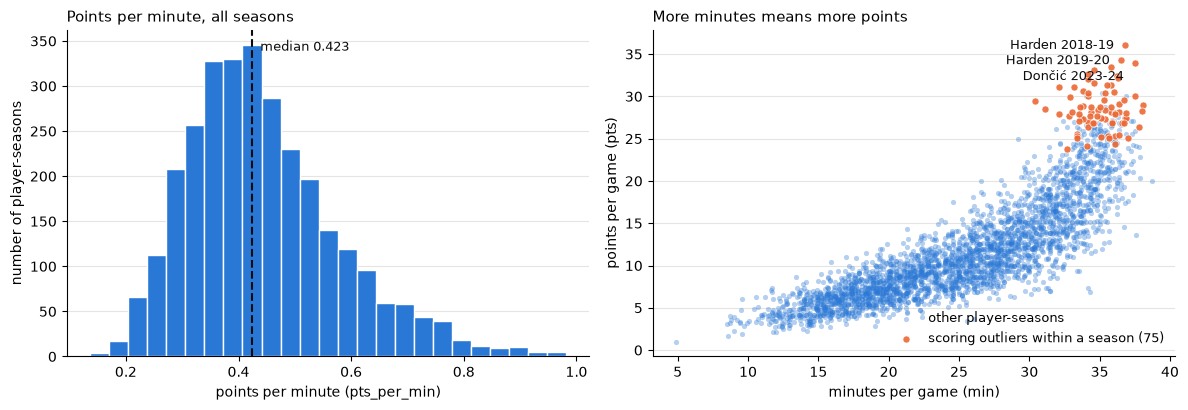

,min,pts,pts_per_min
min,1.00,0.83,0.56
pts,0.83,1.00,0.91
pts_per_min,0.56,0.91,1.00


In [12]:
BLUE, ORANGE, INK = '#2a78d6', '#eb6834', '#0b0b0b'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Left: how points per minute is spread out (all seasons)
ax = axes[0]
ax.hist(nba_clean['pts_per_min'], bins=25, color=BLUE, edgecolor='white', linewidth=1)
med = nba_clean['pts_per_min'].median()
ax.axvline(med, color=INK, linestyle='--', linewidth=1.5)
ax.text(med + 0.015, ax.get_ylim()[1] * 0.97, f'median {med:.3f}', color=INK, va='top', fontsize=9)
ax.set_title('Points per minute, all seasons', loc='left', fontsize=11)
ax.set_xlabel('points per minute (pts_per_min)')
ax.set_ylabel('number of player-seasons')

# Right: minutes vs points, scoring outliers (flagged within each season) in orange
ax = axes[1]
normal = nba_clean[~nba_clean['pts_outlier']]
out = nba_clean[nba_clean['pts_outlier']]
ax.scatter(normal['min'], normal['pts'], s=14, color=BLUE, alpha=0.35, linewidth=0, label='other player-seasons')
ax.scatter(out['min'], out['pts'], s=26, color=ORANGE, alpha=0.9, edgecolor='white', linewidth=0.5,
           label=f'scoring outliers within a season ({len(out)})')
offsets = [(-8, -3), (-8, -3), (-8, -12)]
for (_, r), (dx, dy) in zip(out.nlargest(3, 'pts').iterrows(), offsets):
    ax.annotate(f"{r['player'].split()[-1]} {r['season_label']}", (r['min'], r['pts']),
                xytext=(dx, dy), textcoords='offset points', fontsize=9, color=INK, ha='right')
ax.set_title('More minutes means more points', loc='left', fontsize=11)
ax.set_xlabel('minutes per game (min)')
ax.set_ylabel('points per game (pts)')
ax.legend(frameon=False, loc='lower right', fontsize=9)

for a in axes:
    a.spines[['top', 'right']].set_visible(False)
    a.grid(axis='y', color='#e5e4e0', linewidth=0.8)
    a.set_axisbelow(True)
plt.tight_layout()
plt.show()

nba_clean[['min', 'pts', 'pts_per_min']].corr().round(2)

**What we found:**

- **Points per minute has a long tail on the high side.** Most player-seasons score about 0.3 to 0.55 points per minute, the middle value is 0.423, and a few go up to almost 1.0. The mean is higher than the median, which is what a long right tail looks like.
- **Minutes and points go together.** The more minutes a player gets, the more points he scores (correlation 0.83). This is why we added `pts_per_min`, which compares players on a fairer scale.
- **`pts_per_min` only partly removes the minutes effect.** It still moves with minutes (correlation 0.56), and it is very close to `pts` itself (correlation 0.91). So we treat it as a scoring rate, and we will keep an eye on it when we build the model.
- **The 75 scoring outliers** (orange dots) are at the top of the cloud, mostly players who play heavy minutes (roughly 30 to 38 per game) and score far more than others in the same season. We keep them.
- Remember that this table covers only players who qualify for the leaderboard (see 2B).

## 5. Comparison with the ideal dataset

An ideal dataset for our question would also have advanced stats (net rating, on/off splits), contract details (years left, salary cap apron, trade clauses), playoff results, and injury records. This dataset has the regular-season box-score part: it gives a per-game and per-minute baseline for each qualified player, and Dataset #2 fills in the players who are not on the leaderboard. Playoff results, contract details, and trade records will come from other datasets, and we'll join them in a later checkpoint.